In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD,Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.losses import CategoricalCrossentropy

In [2]:
# Load the dataset from the local file
data = np.load('cifar-10-python.npz')
x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000,)
(10000,)


In [3]:
y_train


array([6, 9, 9, ..., 9, 1, 1], shape=(50000,))

In [4]:
x_train.dtype

dtype('float64')

In [5]:
max_pixel_value=x_train.max()
max_pixel_value

np.float64(255.0)

In [6]:
# Normalize pixel values to be between 0 and 1
max_pixel_value=x_train.max()
x_train = x_train.astype("float32") / max_pixel_value
x_test = x_test.astype("float32") / max_pixel_value

In [7]:
# y_train = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# One-Hot Encoding
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)



In [8]:
# Defining the Model’s Architecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout , Conv2D ,BatchNormalization,MaxPooling2D

model  = Sequential([
    Input(shape=(32,32,3)),

    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Second Convolutional Block
    Conv2D(64,(3,3) , activation = 'relu'), 
    BatchNormalization(), 
    MaxPooling2D((2,2)),
    Dropout(0.25) , 

    # Third Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(64, activation='relu'),
    Dense(32 ,activation= 'relu') , 

    # output layer  
    Dense(10, activation='softmax')
]) 

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,970 (488.16 KB)

 Trainable params: 124,650 (486.91 KB)

 Non-trainable params: 320 (1.25 KB)

In [9]:
#compile the model 

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Accuracy,Precision,Recall

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=CategoricalCrossentropy(),
    metrics=['accuracy', Precision(), Recall()]
)



In [10]:
# Define Early Stopping Callback
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

print("Early stopping callback created successfully!")

Early stopping callback created successfully!


In [11]:
# Train the model with Early Stopping
history = model.fit(
    x_train, y_train,
    epochs=10,                  # Aap max epochs zyada rakh sakte hain, early stop khud rok dega
    batch_size=64,
    validation_data=(x_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.4742 - loss: 1.4724 - precision: 0.6693 - recall: 0.2802 - val_accuracy: 0.5417 - val_loss: 1.2850 - val_precision: 0.7060 - val_recall: 0.3772
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.6092 - loss: 1.1074 - precision: 0.7425 - recall: 0.4737 - val_accuracy: 0.5816 - val_loss: 1.2150 - val_precision: 0.6917 - val_recall: 0.4804
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.6638 - loss: 0.9568 - precision: 0.7774 - recall: 0.5541 - val_accuracy: 0.6066 - val_loss: 1.1565 - val_precision: 0.6913 - val_recall: 0.5363
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.6984 - loss: 0.8624 - precision: 0.7968 - recall: 0.6042 - val_accuracy: 0.6482 - val_loss: 1.0257 - val_precision: 0.7380 - val_recall: 0.5682
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.7187 - loss: 0.7948 - precision: 0.8069 - recall: 0.6360 - val_accuracy: 0.6700 - va

In [18]:
test_loss, test_acc, test_precision, test_recall = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7101 - loss: 0.8454 - precision: 0.7783 - recall: 0.6529
Test Loss: 0.8454299569129944
Test Accuracy: 0.710099995136261
Test Precision: 0.7782810926437378
Test Recall: 0.652899980545044


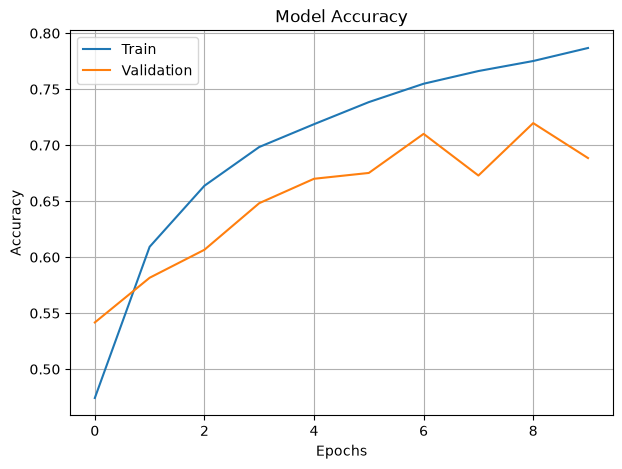

In [19]:
# Plot accuracy curves
plt.figure(figsize=(7,5))
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

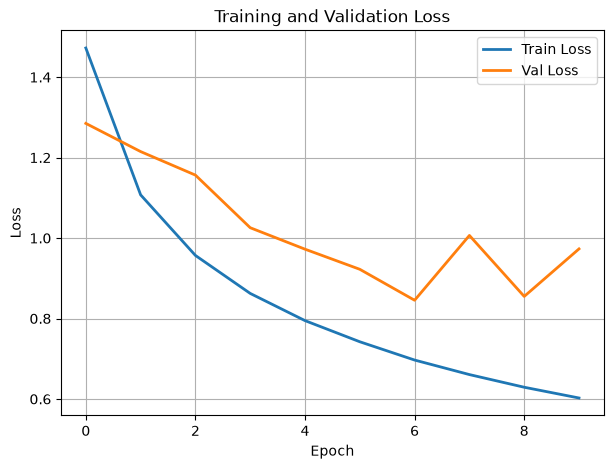

In [20]:
plt.figure(figsize=(7,5))
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)